In [2]:
!python -m pip install --upgrade pip

In [3]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm joblib

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss,
    silhouette_score
)
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    IsolationForest
)
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import MiniBatchKMeans

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
DATA_PATH = "Crop recommendation dataset.csv"

if not os.path.exists(DATA_PATH):
    # Alternative path for environments where the uploaded file is mounted
    alternative_path = "/mnt/data/Crop recommendation dataset.csv"

    if os.path.exists(alternative_path):
        DATA_PATH = alternative_path
    else:
        raise FileNotFoundError(
            "Dataset not found. Put 'Crop recommendation dataset.csv' "
            "in the notebook's working directory or update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded.
Shape: (57000, 23)


,CROPS,TYPE_OF_CROP,SOIL,SEASON,SOWN,HARVESTED,WATER_SOURCE,SOIL_PH,SOIL_PH_HIGH,CROPDURATION,...,WATERREQUIRED,WATERREQUIRED_MAX,RELATIVE_HUMIDITY,RELATIVE_HUMIDITY_MAX,N,N_MAX,P,P_MAX,K,K_MAX
0,rice,cereals,Alluvial soil,kharif,Jun,Sep,irrigated,7.6,8.0,116.9,...,2462.3,2500,73.8,80,82.4,100,40.7,60,42.2,60
1,rice,cereals,Loamy soil,kharif,Jul,Oct,rainfed,6.2,8.0,117.9,...,1237.5,2500,60.9,80,90.5,100,51.3,60,46.2,60
2,rice,cereals,Clay soil,kharif,Jun,Sep,irrigated,6.7,8.0,117.7,...,1075.1,2500,67.5,80,86.2,100,50.7,60,44.4,60
3,rice,cereals,Alluvial soil,kharif,Jul,Oct,rainfed,6.1,8.0,149.8,...,1549.9,2500,73.6,80,91.3,100,51.3,60,44.5,60
4,rice,cereals,Loamy soil,kharif,Jun,Sep,irrigated,8.0,8.0,131.7,...,1306.4,2500,60.3,80,81.3,100,48.6,60,51.0,60


In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(
    df["CROPS"]
      .value_counts()
      .sort_values(ascending=False)
      .to_frame("Number of Records")
)

print("\nNumber of unique crops:", df["CROPS"].nunique())

Dataset shape: (57000, 23)

Column names:
['CROPS', 'TYPE_OF_CROP', 'SOIL', 'SEASON', 'SOWN', 'HARVESTED', 'WATER_SOURCE', 'SOIL_PH', 'SOIL_PH_HIGH', 'CROPDURATION', 'CROPDURATION_MAX', 'TEMP', 'MAX_TEMP', 'WATERREQUIRED', 'WATERREQUIRED_MAX', 'RELATIVE_HUMIDITY', 'RELATIVE_HUMIDITY_MAX', 'N', 'N_MAX', 'P', 'P_MAX', 'K', 'K_MAX']

Data types:


,Data Type
CROPS,object
TYPE_OF_CROP,object
SOIL,object
SEASON,object
SOWN,object
HARVESTED,object
WATER_SOURCE,object
SOIL_PH,float64
SOIL_PH_HIGH,float64
CROPDURATION,float64



Missing values:


,Missing Values
CROPS,0
TYPE_OF_CROP,0
SOIL,0
SEASON,0
SOWN,0
HARVESTED,0
WATER_SOURCE,0
SOIL_PH,0
SOIL_PH_HIGH,0
CROPDURATION,0



Duplicate rows: 0

Target distribution:


,Number of Records
CROPS,
rice,1000
wheat,1000
maize,1000
sorghum,1000
Pearl millet,1000
ragi,1000
panivaragu,1000
samai,1000
thinai,1000



Number of unique crops: 57


In [7]:
EXPECTED_COLUMNS = [
    "CROPS",
    "TYPE_OF_CROP",
    "SOIL",
    "SEASON",
    "SOWN",
    "HARVESTED",
    "WATER_SOURCE",
    "SOIL_PH",
    "SOIL_PH_HIGH",
    "CROPDURATION",
    "CROPDURATION_MAX",
    "TEMP",
    "MAX_TEMP",
    "WATERREQUIRED",
    "WATERREQUIRED_MAX",
    "RELATIVE_HUMIDITY",
    "RELATIVE_HUMIDITY_MAX",
    "N",
    "N_MAX",
    "P",
    "P_MAX",
    "K",
    "K_MAX"
]

missing_columns = set(EXPECTED_COLUMNS) - set(df.columns)
extra_columns = set(df.columns) - set(EXPECTED_COLUMNS)

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if "CROPS" not in df.columns:
    raise ValueError("Target column CROPS is missing.")

print("Schema validation passed.")
print("Missing expected columns:", missing_columns)
print("Additional columns:", extra_columns)

Schema validation passed.
Missing expected columns: set()
Additional columns: set()


In [8]:
df = df.copy()

# Remove rows without a target label
df = df.dropna(subset=["CROPS"])

# Clean categorical columns
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

for column in categorical_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Convert numeric columns safely
numeric_columns = df.select_dtypes(include=["number"]).columns.tolist()

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Shape after basic cleaning:", df.shape)

print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

Shape after basic cleaning: (57000, 23)

Missing values after cleaning:


,Missing Values
CROPS,0
TYPE_OF_CROP,0
SOIL,0
SEASON,0
SOWN,0
HARVESTED,0
WATER_SOURCE,0
SOIL_PH,0
SOIL_PH_HIGH,0
CROPDURATION,0


Target classes: 57
Total records: 57000


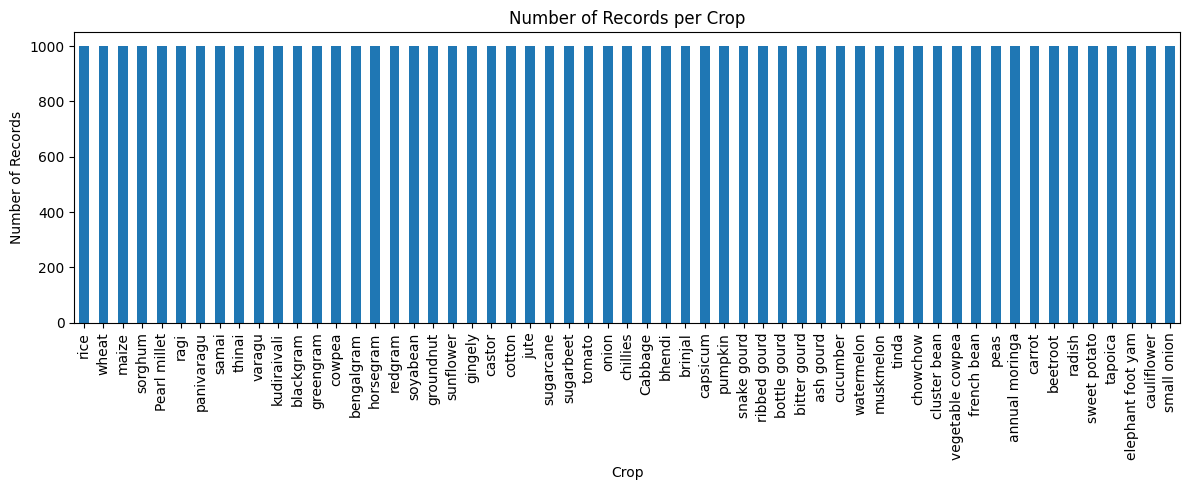

In [9]:
print("Target classes:", df["CROPS"].nunique())
print("Total records:", len(df))

plt.figure(figsize=(12, 5))

df["CROPS"].value_counts().sort_values().plot(kind="bar")

plt.title("Number of Records per Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

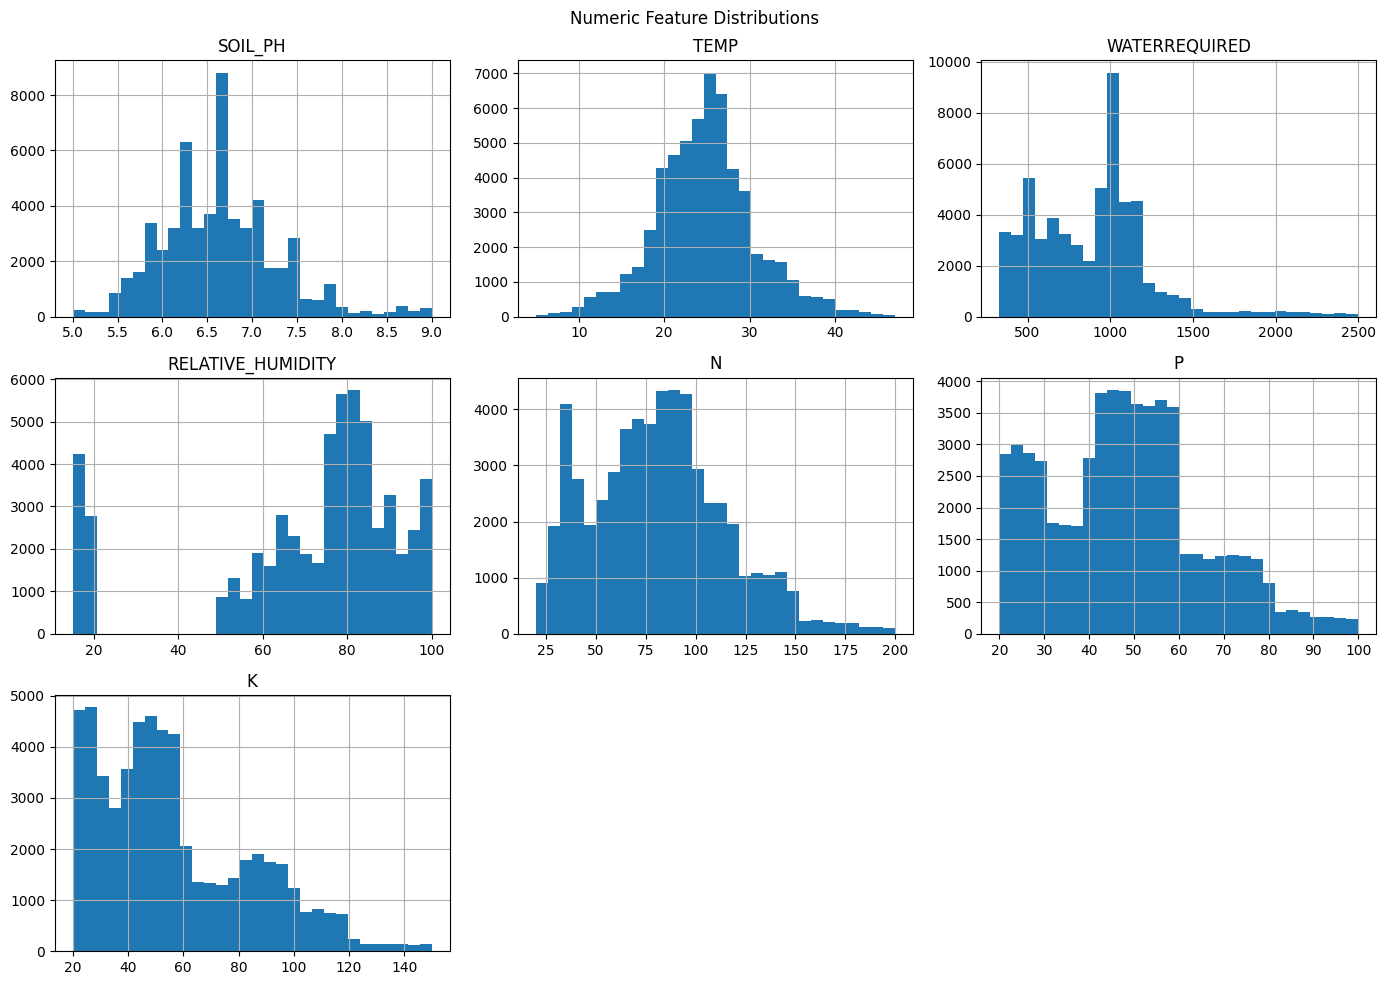

In [10]:
numeric_features = [
    "SOIL_PH",
    "TEMP",
    "WATERREQUIRED",
    "RELATIVE_HUMIDITY",
    "N",
    "P",
    "K"
]

df[numeric_features].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

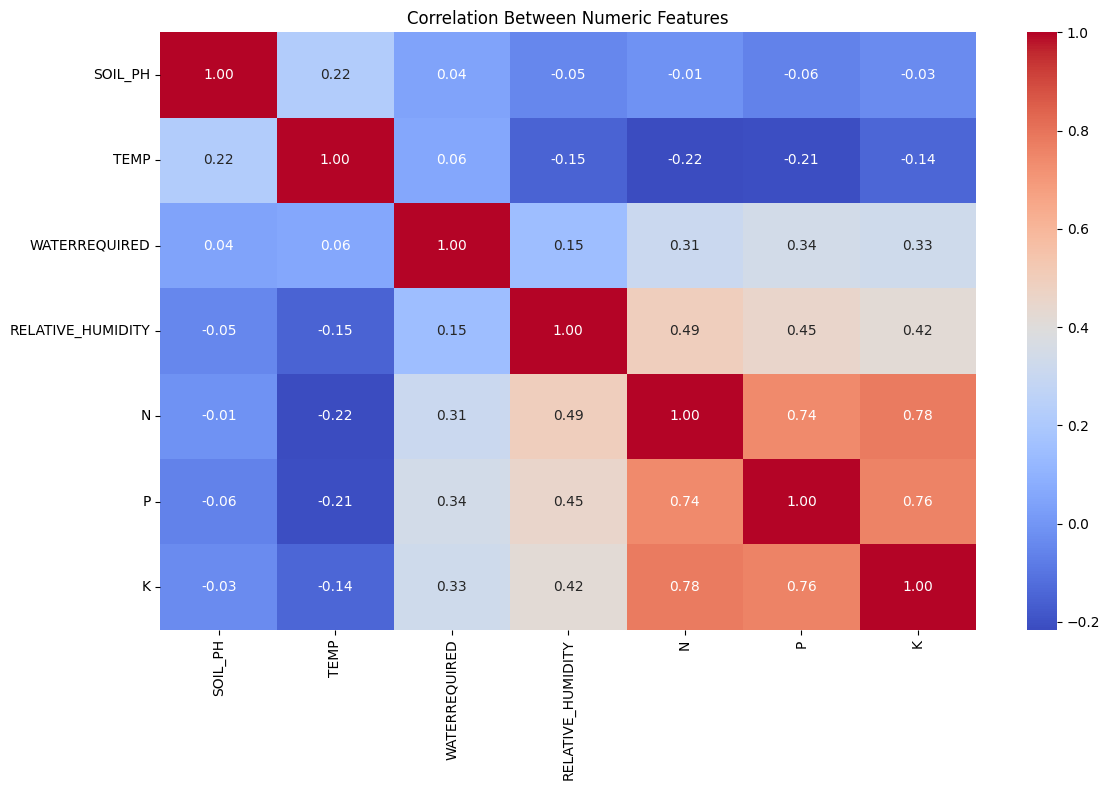

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

In [12]:
target = "CROPS"

leakage_investigation = []

for column in df.columns:
    if column == target:
        continue

    unique_per_crop = (
        df.groupby(target)[column]
          .nunique()
    )

    leakage_investigation.append({
        "Feature": column,
        "Number of Unique Values": df[column].nunique(),
        "Crops Where Feature Is Constant": (
            unique_per_crop == 1
        ).sum(),
        "Total Crop Classes": df[target].nunique(),
        "Constant Within Every Crop": (
            unique_per_crop == 1
        ).all()
    })

leakage_report = pd.DataFrame(leakage_investigation)

display(
    leakage_report.sort_values(
        by="Constant Within Every Crop",
        ascending=False
    )
)

,Feature,Number of Unique Values,Crops Where Feature Is Constant,Total Crop Classes,Constant Within Every Crop
0,TYPE_OF_CROP,10,57,57,True
7,SOIL_PH_HIGH,11,57,57,True
19,P_MAX,7,57,57,True
17,N_MAX,8,57,57,True
15,RELATIVE_HUMIDITY_MAX,15,57,57,True
13,WATERREQUIRED_MAX,16,57,57,True
9,CROPDURATION_MAX,21,57,57,True
11,MAX_TEMP,18,57,57,True
2,SEASON,3,57,57,True
21,K_MAX,9,57,57,True


In [13]:
season_crop_table = pd.crosstab(
    df["CROPS"],
    df["SEASON"]
)

display(season_crop_table)

season_unique_per_crop = df.groupby("CROPS")["SEASON"].nunique()

print(
    "Crop classes with only one season:",
    (season_unique_per_crop == 1).sum()
)

print(
    "Total crop classes:",
    df["CROPS"].nunique()
)

SEASON,Zaid,kharif,rabi
CROPS,,,
Cabbage,1000,0,0
Pearl millet,0,1000,0
annual moringa,1000,0,0
ash gourd,1000,0,0
beetroot,0,0,1000
bengalgram,0,0,1000
bhendi,1000,0,0
bitter gourd,1000,0,0
blackgram,0,0,1000


Crop classes with only one season: 57
Total crop classes: 57


In [14]:
CORE_CATEGORICAL_FEATURES = [
    "SOIL",
    "SOWN",
    "WATER_SOURCE"
]

CORE_NUMERIC_FEATURES = [
    "SOIL_PH",
    "TEMP",
    "RELATIVE_HUMIDITY",
    "N",
    "P",
    "K"
]

CORE_FEATURES = (
    CORE_CATEGORICAL_FEATURES +
    CORE_NUMERIC_FEATURES
)

SEASON_FEATURES = CORE_FEATURES + ["SEASON"]

# Optional experiment:
# Only enable this if WATERREQUIRED is a genuine user-provided input,
# not the expected water requirement of the crop being predicted.
WATERREQUIRED_IS_USER_INPUT = False

FEATURE_SETS = {
    "core_without_season": CORE_FEATURES,
    "core_with_season": SEASON_FEATURES
}

if WATERREQUIRED_IS_USER_INPUT:
    FEATURE_SETS["extended_with_water"] = (
        CORE_FEATURES + ["WATERREQUIRED"]
    )

    FEATURE_SETS["extended_with_season_and_water"] = (
        SEASON_FEATURES + ["WATERREQUIRED"]
    )

print("Feature sets to compare:")

for name, features in FEATURE_SETS.items():
    print(f"\n{name}")
    print(features)

Feature sets to compare:

core_without_season
['SOIL', 'SOWN', 'WATER_SOURCE', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K']

core_with_season
['SOIL', 'SOWN', 'WATER_SOURCE', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K', 'SEASON']


In [15]:
X = df.drop(columns=["CROPS"])
y = df["CROPS"].astype(str)

# Encode target labels for compatibility with XGBoost
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("Number of classes:", len(class_names))
print("Classes:")
print(class_names)

# First: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    stratify=y_encoded,
    random_state=RANDOM_STATE
)

# Split temporary set equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("\nSplit sizes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Number of classes: 57
Classes:
['Cabbage' 'Pearl millet' 'annual moringa' 'ash gourd' 'beetroot'
 'bengalgram' 'bhendi' 'bitter gourd' 'blackgram' 'bottle gourd' 'brinjal'
 'capsicum' 'carrot' 'castor' 'cauliflower' 'chillies' 'chowchow'
 'cluster bean' 'cotton' 'cowpea' 'cucumber' 'elephant foot yam'
 'french bean' 'gingely' 'greengram' 'groundnut' 'horsegram' 'jute'
 'kudiraivali' 'maize' 'muskmelon' 'onion' 'panivaragu' 'peas' 'pumpkin'
 'radish' 'ragi' 'redgram' 'ribbed gourd' 'rice' 'samai' 'small onion'
 'snake gourd' 'sorghum' 'soyabean' 'sugarbeet' 'sugarcane' 'sunflower'
 'sweet potato' 'tapoica' 'thinai' 'tinda' 'tomato' 'varagu'
 'vegetable cowpea' 'watermelon' 'wheat']

Split sizes:
Training: (39900, 22)
Validation: (8550, 22)
Testing: (8550, 22)


In [16]:
def create_one_hot_encoder():
    """
    Supports both newer and older scikit-learn versions.
    """
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )


def build_preprocessor(feature_columns):
    categorical = [
        column
        for column in feature_columns
        if df[column].dtype == "object" or
           str(df[column].dtype).startswith("string")
    ]

    numerical = [
        column
        for column in feature_columns
        if column not in categorical
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", create_one_hot_encoder())
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numerical),
            ("categorical", categorical_pipeline, categorical)
        ],
        remainder="drop",
        sparse_threshold=0
    )

    return preprocessor

In [17]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def create_models():
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1500,
            solver="lbfgs",
            n_jobs=-1
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "Extra Trees": ExtraTreesClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "XGBoost": XGBClassifier(
            objective="multi:softprob",
            eval_metric="mlogloss",
            n_estimators=250,
            max_depth=7,
            learning_rate=0.08,
            subsample=0.85,
            colsample_bytree=0.85,
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

        "LightGBM": LGBMClassifier(
            objective="multiclass",
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=-1
        )
    }

    return models

In [25]:
results = []
trained_models = {}

for feature_set_name, feature_columns in FEATURE_SETS.items():

    print("\n" + "=" * 70)
    print("FEATURE SET:", feature_set_name)
    print("=" * 70)

    X_train_fs = X_train[feature_columns]
    X_val_fs = X_val[feature_columns]

    # IMPORTANT:
    # Create fresh model instances for every feature set.
    # Never reuse fitted classifier objects across pipelines.
    models = create_models()

    for model_name, classifier in models.items():

        print(f"\nTraining {model_name}...")

        preprocessor = build_preprocessor(feature_columns)

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ])

        pipeline.fit(X_train_fs, y_train)

        val_predictions = pipeline.predict(X_val_fs)

        accuracy = accuracy_score(
            y_val,
            val_predictions
        )

        macro_precision = precision_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_val,
            val_predictions,
            average="weighted",
            zero_division=0
        )

        results.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro Precision": macro_precision,
            "Macro Recall": macro_recall,
            "Macro F1": macro_f1,
            "Weighted F1": weighted_f1
        })

        # Each dictionary entry now holds an independent pipeline
        trained_models[
            (feature_set_name, model_name)
        ] = pipeline

        print(
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f}"
        )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True)
)

print("\nAll models trained independently.")


FEATURE SET: core_without_season

Training Logistic Regression...
Accuracy: 0.9577 | Macro F1: 0.9573

Training Random Forest...
Accuracy: 0.9848 | Macro F1: 0.9848

Training Extra Trees...
Accuracy: 0.9750 | Macro F1: 0.9750

Training XGBoost...
Accuracy: 0.9822 | Macro F1: 0.9822

Training LightGBM...
Accuracy: 0.9811 | Macro F1: 0.9811

FEATURE SET: core_with_season

Training Logistic Regression...
Accuracy: 0.9630 | Macro F1: 0.9628

Training Random Forest...
Accuracy: 0.9844 | Macro F1: 0.9844

Training Extra Trees...
Accuracy: 0.9766 | Macro F1: 0.9766

Training XGBoost...
Accuracy: 0.9820 | Macro F1: 0.9820

Training LightGBM...
Accuracy: 0.9819 | Macro F1: 0.9819


,Feature Set,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,core_without_season,Random Forest,0.984795,0.985489,0.984795,0.984779,0.984779
1,core_with_season,Random Forest,0.984444,0.984958,0.984444,0.984448,0.984448
2,core_without_season,XGBoost,0.982222,0.982550,0.982222,0.982216,0.982216
3,core_with_season,XGBoost,0.981988,0.982305,0.981988,0.981997,0.981997
4,core_with_season,LightGBM,0.981871,0.982177,0.981871,0.981906,0.981906
5,core_without_season,LightGBM,0.981053,0.981322,0.981053,0.981095,0.981095
6,core_with_season,Extra Trees,0.976608,0.977342,0.976608,0.976594,0.976594
7,core_without_season,Extra Trees,0.974971,0.975710,0.974971,0.974969,0.974969
8,core_with_season,Logistic Regression,0.963041,0.963258,0.963041,0.962791,0.962791
9,core_without_season,Logistic Regression,0.957661,0.957997,0.957661,0.957340,0.957340



All models trained independently.


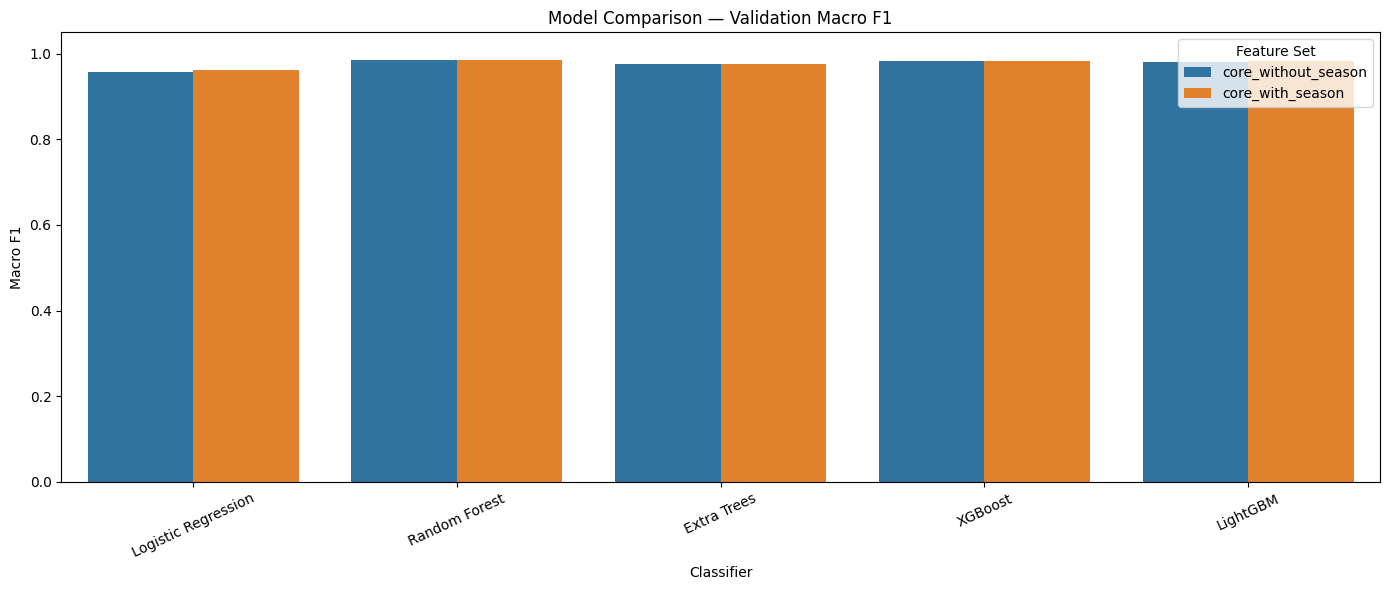

In [26]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro F1",
    hue="Feature Set"
)

plt.title("Model Comparison — Validation Macro F1")
plt.xlabel("Classifier")
plt.ylabel("Macro F1")
plt.xticks(rotation=25)
plt.ylim(0, 1.05)
plt.legend(title="Feature Set")
plt.tight_layout()
plt.show()

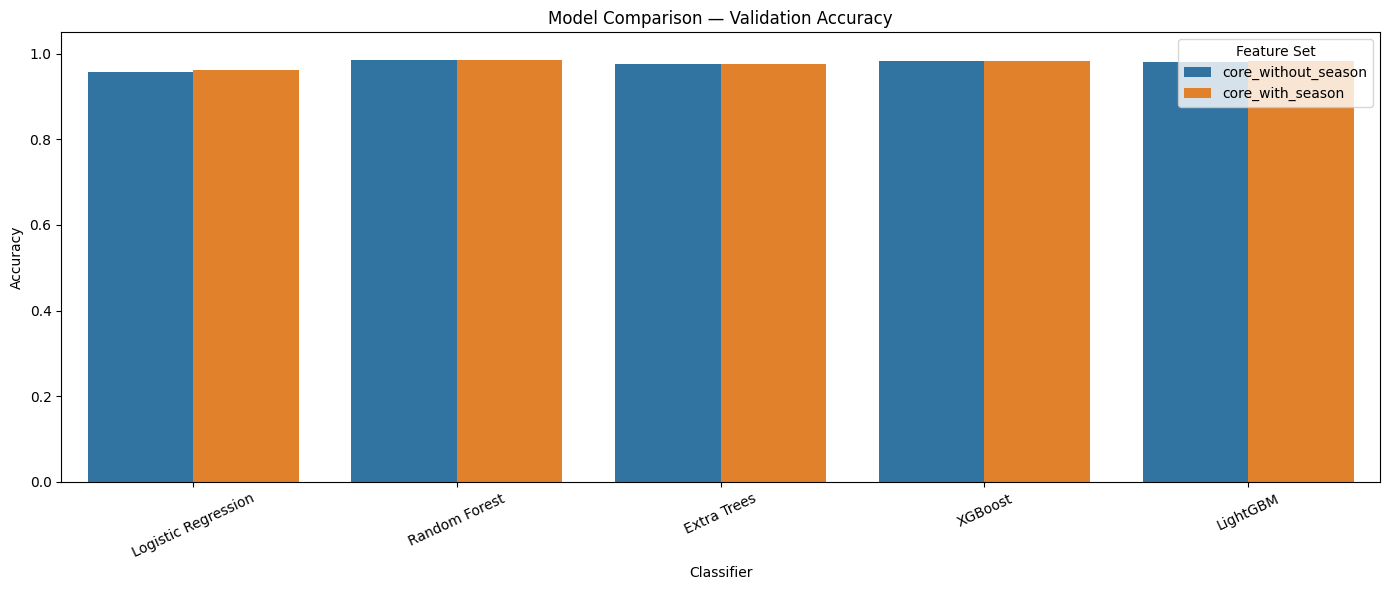

In [27]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Feature Set"
)

plt.title("Model Comparison — Validation Accuracy")
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.xticks(rotation=25)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [28]:
best_result = (
    results_df
    .sort_values(
        by=["Macro F1", "Accuracy"],
        ascending=False
    )
    .iloc[0]
)

best_feature_set_name = best_result["Feature Set"]
best_model_name = best_result["Model"]

best_model = trained_models[
    (best_feature_set_name, best_model_name)
]

best_features = FEATURE_SETS[best_feature_set_name]

print("Selected feature set:", best_feature_set_name)
print("Selected model:", best_model_name)

print("Validation accuracy:", round(best_result["Accuracy"], 4))
print("Validation macro F1:", round(best_result["Macro F1"], 4))

print("\nRaw input feature count:", len(best_features))

print(
    "Encoded feature count:",
    best_model.named_steps["preprocessor"].transform(
        X_train[best_features].iloc[:5]
    ).shape[1]
)

print(
    "Classifier expected feature count:",
    best_model.named_steps["classifier"].n_features_in_
)

Selected feature set: core_without_season
Selected model: Random Forest
Validation accuracy: 0.9848
Validation macro F1: 0.9848

Raw input feature count: 9
Encoded feature count: 48
Classifier expected feature count: 48


In [29]:
if not WATERREQUIRED_IS_USER_INPUT:

    print(
        "Skipped: WATERREQUIRED is not confirmed as a genuine "
        "pre-recommendation input."
    )

else:

    extended_features = CORE_FEATURES + ["WATERREQUIRED"]

    extended_pipeline = Pipeline([
        ("preprocessor", build_preprocessor(extended_features)),
        ("classifier", create_models()[best_model_name])
    ])

    extended_pipeline.fit(
        X_train[extended_features],
        y_train
    )

    extended_predictions = extended_pipeline.predict(
        X_val[extended_features]
    )

    extended_macro_f1 = f1_score(
        y_val,
        extended_predictions,
        average="macro",
        zero_division=0
    )

    print("Original validation Macro F1:", best_result["Macro F1"])
    print("Extended validation Macro F1:", extended_macro_f1)

Skipped: WATERREQUIRED is not confirmed as a genuine pre-recommendation input.


In [30]:
X_test_selected = X_test[best_features]

# Safety check before prediction
X_test_transformed = best_model.named_steps["preprocessor"].transform(
    X_test_selected
)

expected_features = (
    best_model.named_steps["classifier"].n_features_in_
)

actual_features = X_test_transformed.shape[1]

print("Features expected by classifier:", expected_features)
print("Features produced by preprocessing:", actual_features)

assert expected_features == actual_features, (
    "Feature mismatch detected. Check the selected pipeline."
)

test_predictions = best_model.predict(
    X_test_selected
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_macro_f1,
        test_weighted_f1
    ]
})

display(final_metrics)

Features expected by classifier: 48
Features produced by preprocessing: 48


,Metric,Score
0,Accuracy,0.986550
1,Macro Precision,0.986934
2,Macro Recall,0.986550
3,Macro F1,0.986525
4,Weighted F1,0.986525


In [31]:
class_report = classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(class_report).T

class_report_df = class_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

display(
    class_report_df.sort_values(
        by="f1-score",
        ascending=True
    )
)

,precision,recall,f1-score,support
castor,0.856115,0.793333,0.823529,150.0
sunflower,0.807453,0.866667,0.836013,150.0
ribbed gourd,0.948148,0.853333,0.898246,150.0
muskmelon,0.870588,0.986667,0.925000,150.0
chillies,0.992806,0.920000,0.955017,150.0
onion,0.925466,0.993333,0.958199,150.0
bottle gourd,0.972603,0.946667,0.959459,150.0
rice,0.973154,0.966667,0.969900,150.0
annual moringa,1.000000,0.953333,0.976109,150.0
cotton,0.979866,0.973333,0.976589,150.0


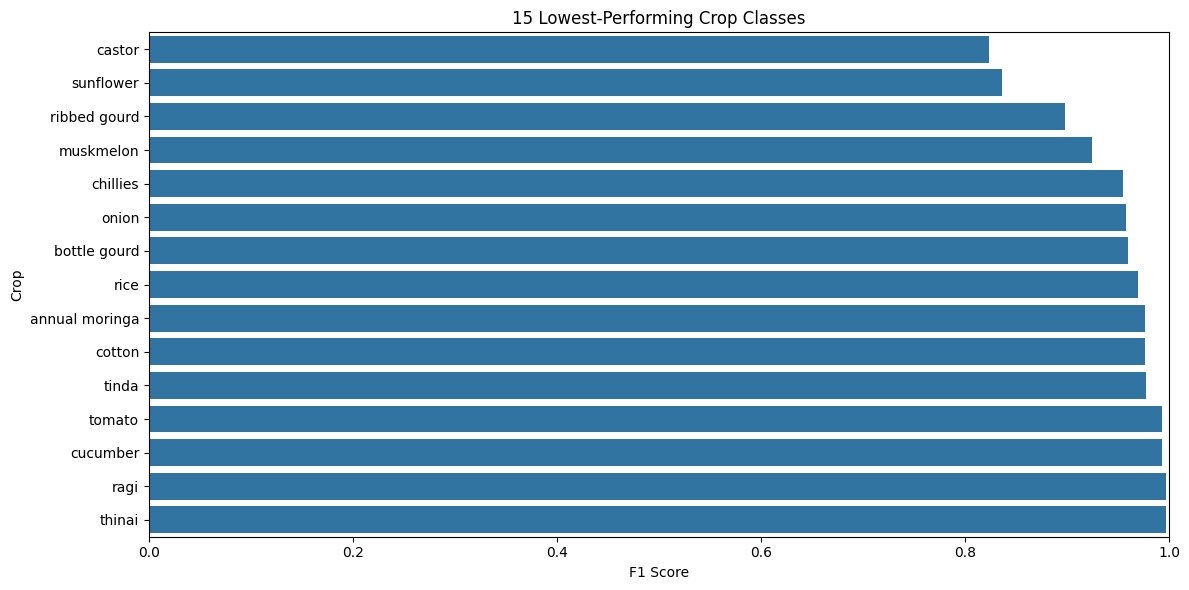

In [32]:
lowest_performing = (
    class_report_df
    .sort_values("f1-score")
    .head(15)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=lowest_performing.reset_index(),
    x="f1-score",
    y="index"
)

plt.title("15 Lowest-Performing Crop Classes")
plt.xlabel("F1 Score")
plt.ylabel("Crop")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

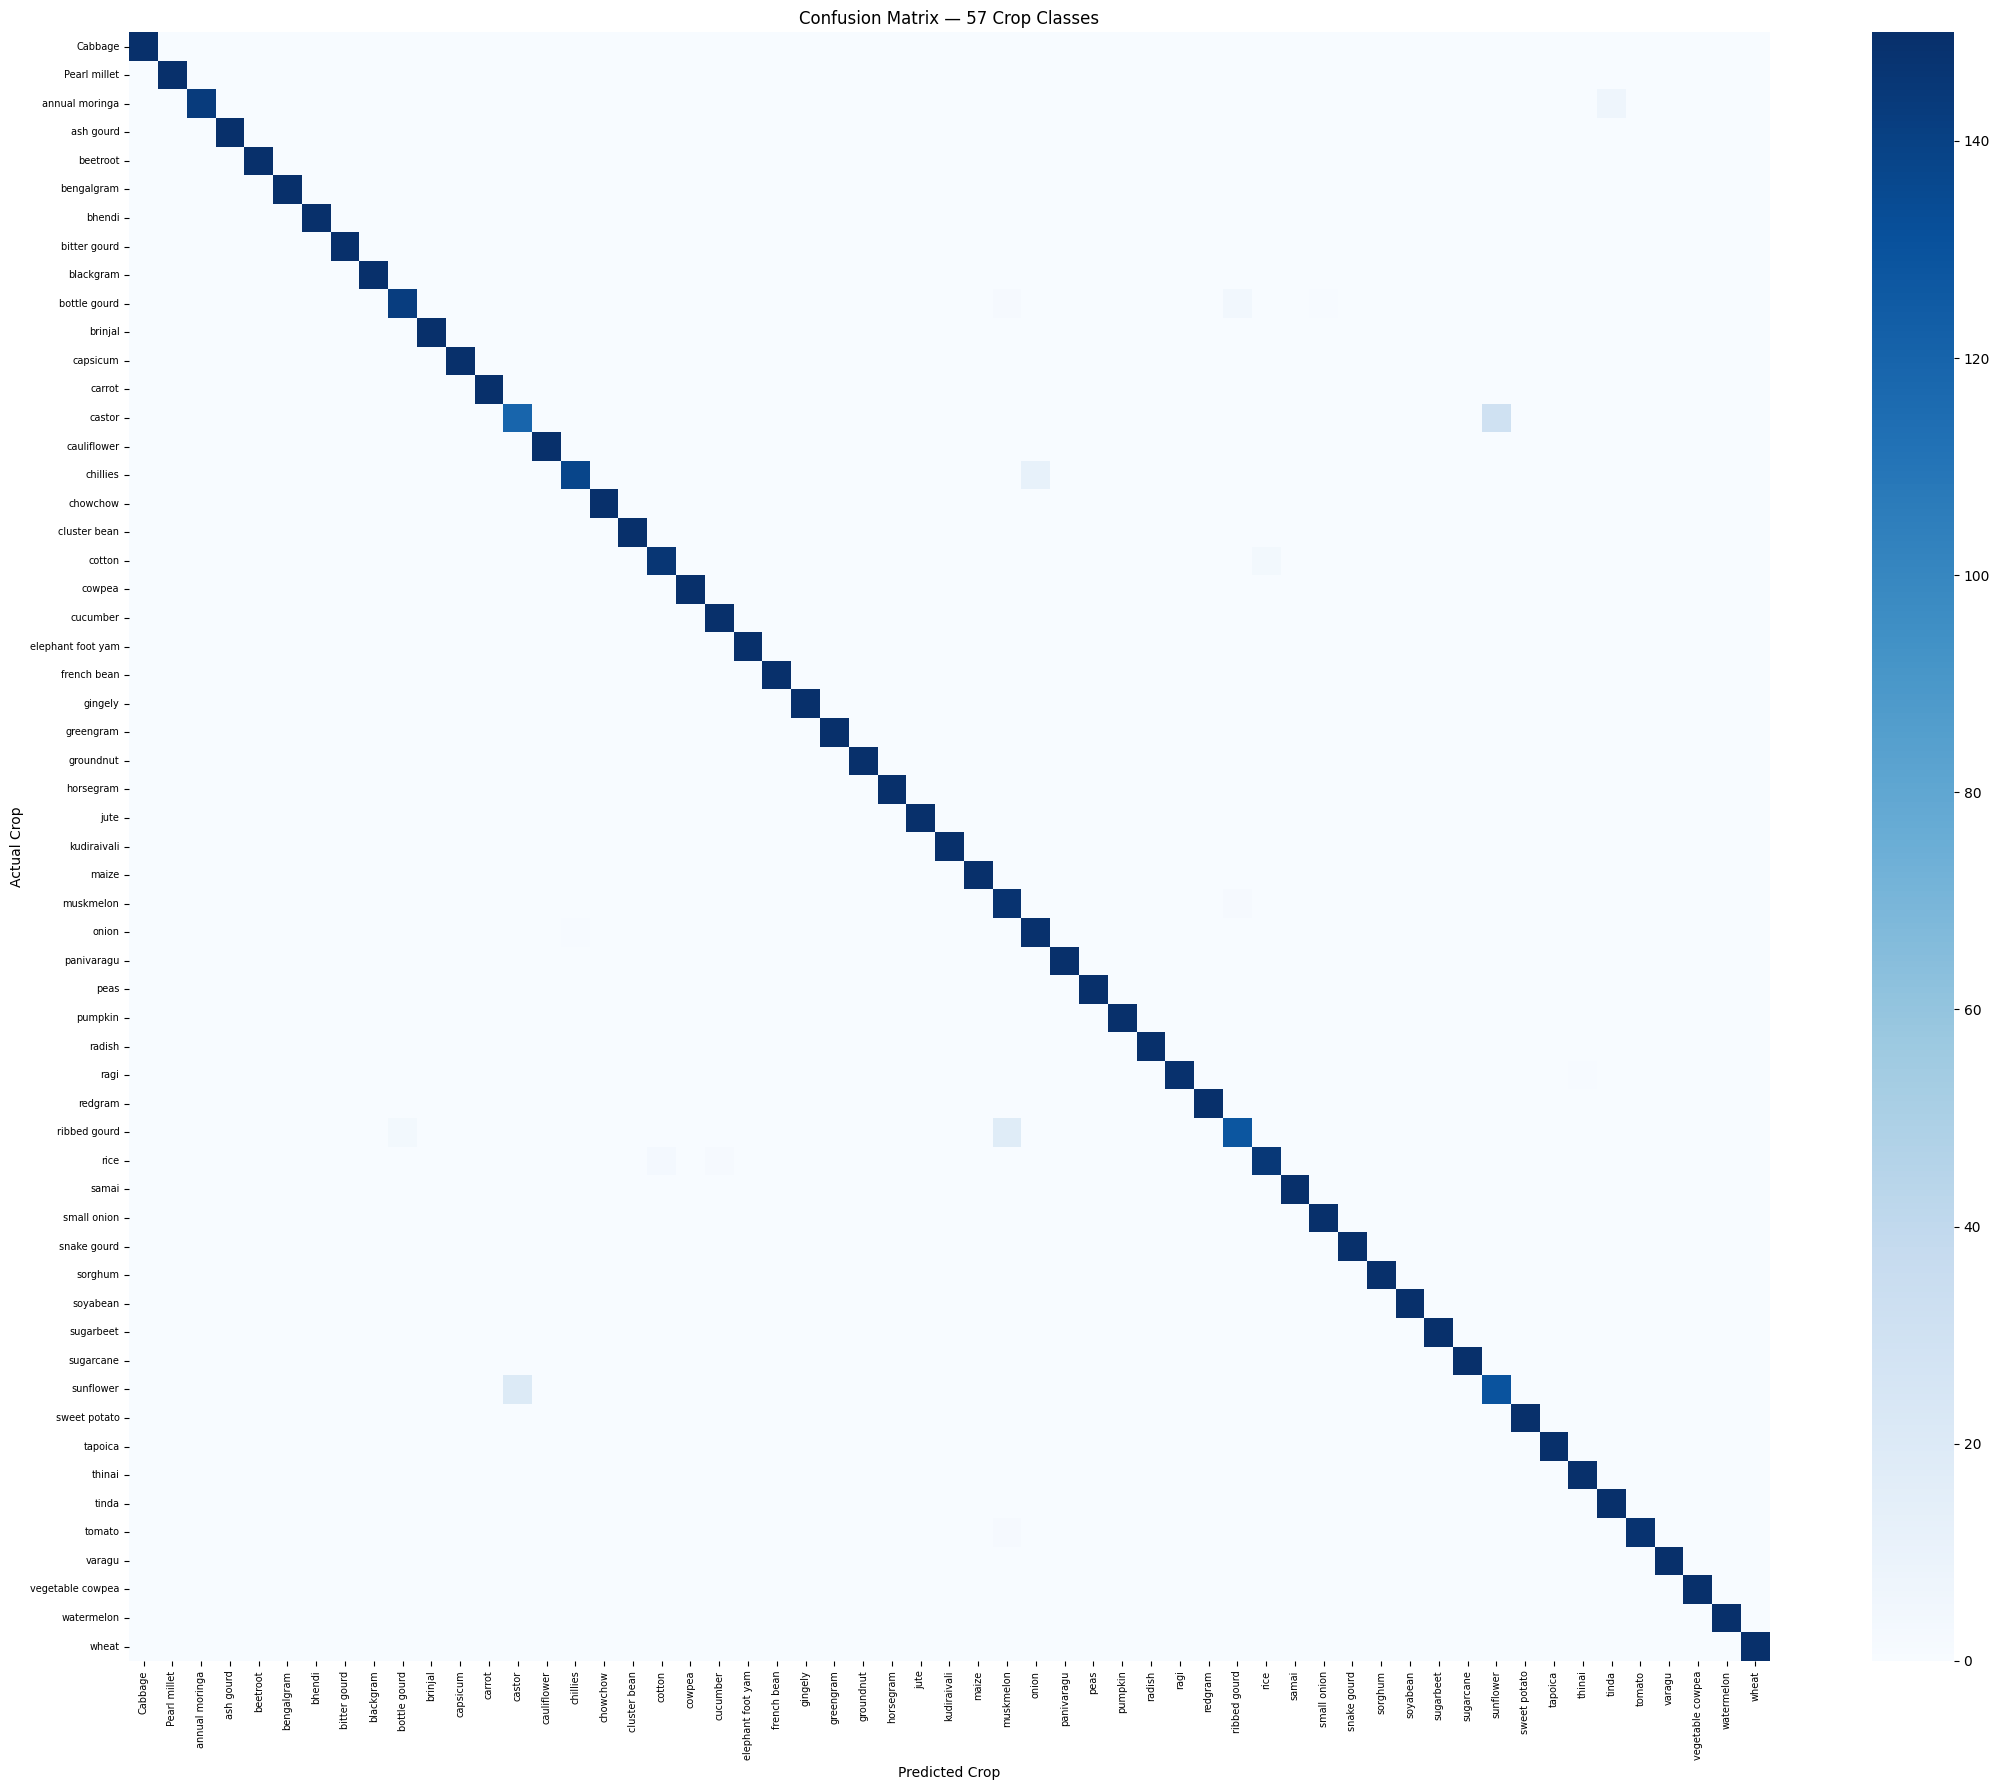

In [33]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(22, 18))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — 57 Crop Classes")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

In [34]:
test_probabilities = best_model.predict_proba(
    X_test_selected
)

test_log_loss = log_loss(
    y_test,
    test_probabilities,
    labels=np.arange(len(class_names))
)

one_hot_test = np.eye(len(class_names))[y_test]

multiclass_brier = np.mean(
    np.sum(
        (test_probabilities - one_hot_test) ** 2,
        axis=1
    )
)

print("Test Log Loss:", round(test_log_loss, 4))
print("Multiclass Brier Score:", round(multiclass_brier, 4))

Test Log Loss: 0.081
Multiclass Brier Score: 0.03


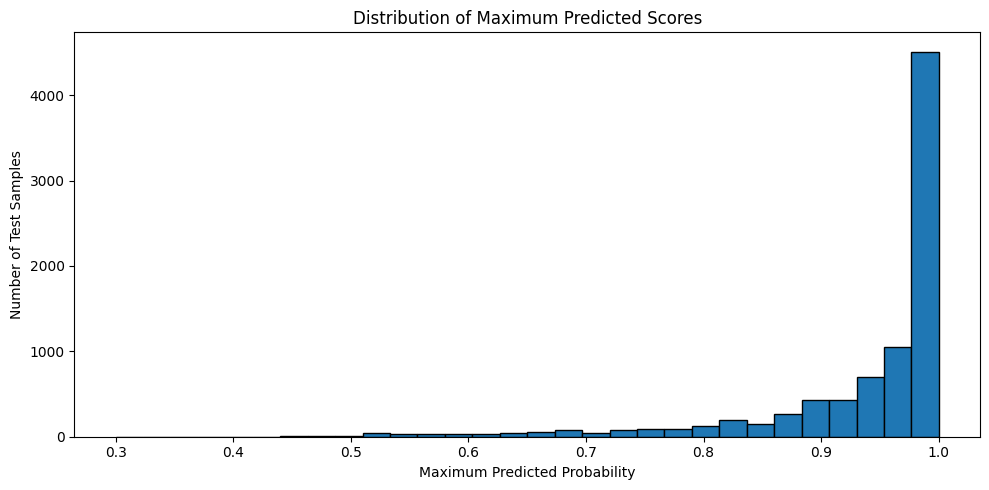

In [36]:
maximum_probabilities = test_probabilities.max(axis=1)

plt.figure(figsize=(10, 5))

plt.hist(
    maximum_probabilities,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Maximum Predicted Scores")
plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Test Samples")
plt.tight_layout()
plt.show()

In [37]:
CLUSTER_FEATURES = [
    "SOIL_PH",
    "TEMP",
    "RELATIVE_HUMIDITY",
    "N",
    "P",
    "K"
]

cluster_scaler = StandardScaler()

X_cluster_train = cluster_scaler.fit_transform(
    X_train[CLUSTER_FEATURES]
)

X_cluster_test = cluster_scaler.transform(
    X_test[CLUSTER_FEATURES]
)

print("Clustering data prepared.")
print("Training matrix:", X_cluster_train.shape)

Clustering data prepared.
Training matrix: (39900, 6)


,K,Silhouette Score
0,3,0.245048
1,4,0.225388
2,5,0.198654
3,6,0.211344
4,7,0.219076
5,8,0.221007
6,9,0.195630
7,10,0.198791


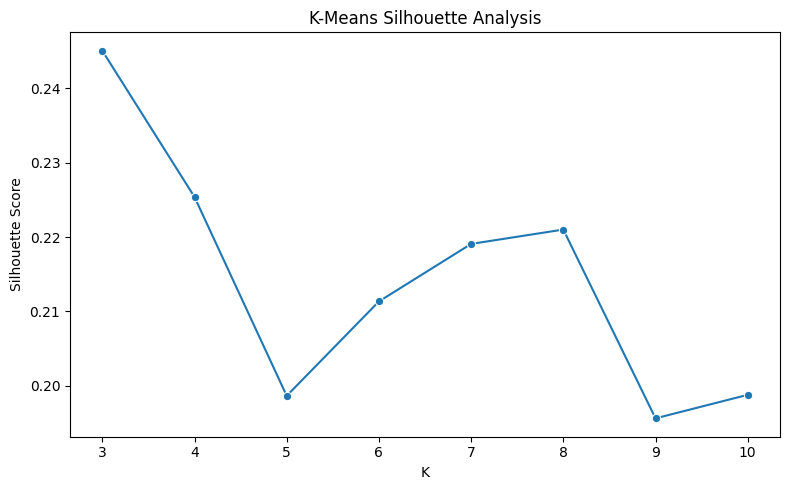

In [38]:
from sklearn.cluster import KMeans

cluster_sample_size = min(5000, len(X_cluster_train))

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(X_cluster_train),
    size=cluster_sample_size,
    replace=False
)

X_cluster_sample = X_cluster_train[sample_indices]

silhouette_results = []

for k in [3, 4, 5, 6, 7, 8, 9, 10]:

    kmeans_test = MiniBatchKMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        batch_size=2048,
        n_init=10
    )

    labels = kmeans_test.fit_predict(X_cluster_sample)

    score = silhouette_score(
        X_cluster_sample,
        labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=silhouette_df,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("K-Means Silhouette Analysis")
plt.tight_layout()
plt.show()

In [39]:
BEST_K = int(
    silhouette_df.sort_values(
        "Silhouette Score",
        ascending=False
    ).iloc[0]["K"]
)

kmeans = MiniBatchKMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    batch_size=2048,
    n_init=10
)

kmeans.fit(X_cluster_train)

train_cluster_labels = kmeans.predict(X_cluster_train)

cluster_analysis = X_train[CLUSTER_FEATURES].copy()
cluster_analysis["Cluster"] = train_cluster_labels
cluster_analysis["Actual Crop"] = label_encoder.inverse_transform(y_train)

print("Selected K:", BEST_K)

print("\nCluster sizes:")
display(
    cluster_analysis["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Records")
)

print("\nMost common crops in each cluster:")
display(
    pd.crosstab(
        cluster_analysis["Cluster"],
        cluster_analysis["Actual Crop"]
    )
)

Selected K: 3

Cluster sizes:


,Number of Records
Cluster,
0,7081
1,20590
2,12229



Most common crops in each cluster:


Actual Crop,Cabbage,Pearl millet,annual moringa,ash gourd,beetroot,bengalgram,bhendi,bitter gourd,blackgram,bottle gourd,...,sunflower,sweet potato,tapoica,thinai,tinda,tomato,varagu,vegetable cowpea,watermelon,wheat
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0,3,0,0,0,419,0,0,700,0,...,0,0,0,700,0,0,700,0,0,0
1,0,697,657,207,699,281,0,187,0,186,...,700,660,700,0,698,0,0,700,161,645
2,700,0,43,493,1,0,700,513,0,514,...,0,40,0,0,2,700,0,0,539,55


In [40]:
OOD_FEATURES = CORE_FEATURES

ood_preprocessor = build_preprocessor(OOD_FEATURES)

X_ood_train = ood_preprocessor.fit_transform(
    X_train[OOD_FEATURES]
)

X_ood_val = ood_preprocessor.transform(
    X_val[OOD_FEATURES]
)

X_ood_test = ood_preprocessor.transform(
    X_test[OOD_FEATURES]
)

print("OOD training matrix:", X_ood_train.shape)

OOD training matrix: (39900, 48)


In [41]:
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    max_samples="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_forest.fit(X_ood_train)

# Higher decision_function values mean more normal observations
val_ood_scores = isolation_forest.decision_function(
    X_ood_val
)

test_ood_scores = isolation_forest.decision_function(
    X_ood_test
)

# Flag approximately 5% of validation records as unusual
OOD_VALIDATION_PERCENTILE = 5

ood_threshold = np.percentile(
    val_ood_scores,
    OOD_VALIDATION_PERCENTILE
)

val_ood_flags = val_ood_scores < ood_threshold
test_ood_flags = test_ood_scores < ood_threshold

print("OOD threshold:", ood_threshold)

print(
    "Validation flagged rate:",
    round(val_ood_flags.mean() * 100, 2),
    "%"
)

print(
    "Test flagged rate:",
    round(test_ood_flags.mean() * 100, 2),
    "%"
)

OOD threshold: 0.0721138725004656
Validation flagged rate: 5.01 %
Test flagged rate: 5.08 %


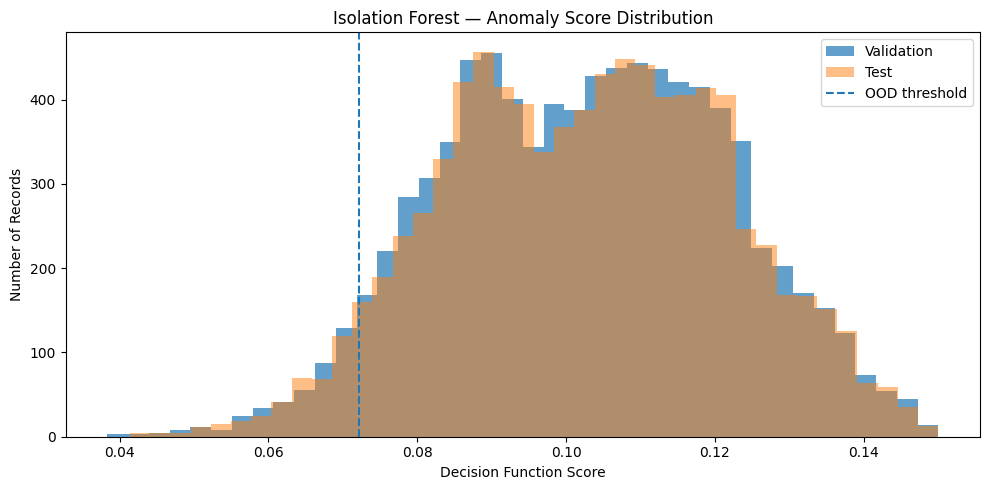

In [42]:
plt.figure(figsize=(10, 5))

plt.hist(
    val_ood_scores,
    bins=40,
    alpha=0.7,
    label="Validation"
)

plt.hist(
    test_ood_scores,
    bins=40,
    alpha=0.5,
    label="Test"
)

plt.axvline(
    ood_threshold,
    linestyle="--",
    label="OOD threshold"
)

plt.title("Isolation Forest — Anomaly Score Distribution")
plt.xlabel("Decision Function Score")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()

,Total,Flagged,Flagged_Rate
Actual Crop,,,
blackgram,150,116,0.773333
sugarcane,150,62,0.413333
horsegram,150,56,0.373333
carrot,150,45,0.300000
bengalgram,150,38,0.253333
bhendi,150,26,0.173333
tapoica,150,19,0.126667
maize,150,17,0.113333
samai,150,17,0.113333


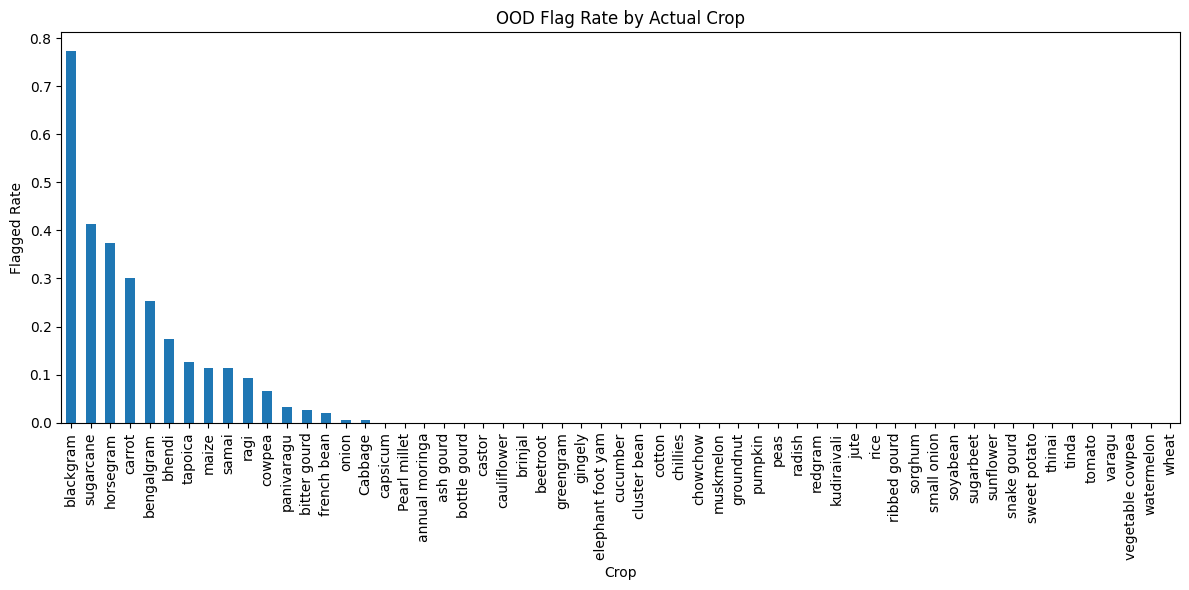

In [43]:
ood_test_analysis = pd.DataFrame({
    "Actual Crop": label_encoder.inverse_transform(y_test),
    "OOD Score": test_ood_scores,
    "Flagged as OOD": test_ood_flags
})

ood_by_crop = (
    ood_test_analysis
    .groupby("Actual Crop")
    .agg(
        Total=("Flagged as OOD", "size"),
        Flagged=("Flagged as OOD", "sum"),
        Flagged_Rate=("Flagged as OOD", "mean")
    )
    .sort_values("Flagged_Rate", ascending=False)
)

display(ood_by_crop)

plt.figure(figsize=(12, 6))

ood_by_crop["Flagged_Rate"].plot(kind="bar")

plt.title("OOD Flag Rate by Actual Crop")
plt.xlabel("Crop")
plt.ylabel("Flagged Rate")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [44]:
def perturb_features(data, percentage, random_state=42):
    """
    Add controlled noise to numeric environmental features.
    Categorical variables remain unchanged.
    """
    perturbed = data.copy()

    rng = np.random.default_rng(random_state)

    for column in CORE_NUMERIC_FEATURES:

        if column == "SOIL_PH":
            noise = rng.normal(
                loc=0,
                scale=0.1 if percentage == 0.05 else 0.2,
                size=len(perturbed)
            )

            perturbed[column] = (
                perturbed[column] + noise
            )

        else:
            noise = rng.normal(
                loc=0,
                scale=percentage,
                size=len(perturbed)
            )

            perturbed[column] = (
                perturbed[column] * (1 + noise)
            )

    return perturbed

In [45]:
baseline_predictions = best_model.predict(
    X_test[best_features]
)

robustness_results = []

for percentage in [0.05, 0.10]:

    perturbed_test = perturb_features(
        X_test,
        percentage=percentage,
        random_state=RANDOM_STATE
    )

    perturbed_predictions = best_model.predict(
        perturbed_test[best_features]
    )

    stability = np.mean(
        baseline_predictions == perturbed_predictions
    )

    changed_rate = 1 - stability

    robustness_results.append({
        "Perturbation": f"{int(percentage * 100)}%",
        "Prediction Stability": stability,
        "Prediction Change Rate": changed_rate
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)

,Perturbation,Prediction Stability,Prediction Change Rate
0,5%,0.908421,0.091579
1,10%,0.815906,0.184094


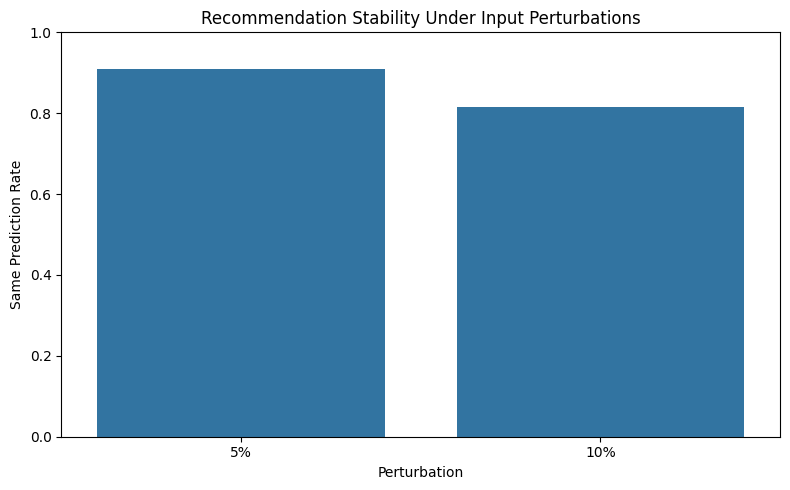

In [46]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=robustness_df,
    x="Perturbation",
    y="Prediction Stability"
)

plt.title("Recommendation Stability Under Input Perturbations")
plt.ylim(0, 1)
plt.ylabel("Same Prediction Rate")
plt.tight_layout()
plt.show()

In [47]:
synthetic_ood_results = []

for percentage in [0.05, 0.10, 0.25]:

    perturbed = perturb_features(
        X_test,
        percentage=percentage,
        random_state=RANDOM_STATE
    )

    perturbed_ood_matrix = ood_preprocessor.transform(
        perturbed[OOD_FEATURES]
    )

    perturbed_scores = isolation_forest.decision_function(
        perturbed_ood_matrix
    )

    flagged_rate = np.mean(
        perturbed_scores < ood_threshold
    )

    synthetic_ood_results.append({
        "Perturbation": f"{int(percentage * 100)}%",
        "Average Anomaly Score": perturbed_scores.mean(),
        "OOD Flag Rate": flagged_rate
    })

synthetic_ood_df = pd.DataFrame(synthetic_ood_results)

display(synthetic_ood_df)

,Perturbation,Average Anomaly Score,OOD Flag Rate
0,5%,0.102269,0.052164
1,10%,0.101076,0.062105
2,25%,0.095620,0.110643


In [48]:
# Observed ranges from the training data only
TRAINING_NUMERIC_RANGES = {}

for column in CORE_NUMERIC_FEATURES:
    TRAINING_NUMERIC_RANGES[column] = (
        float(X_train[column].min()),
        float(X_train[column].max())
    )

# Known categorical values from the training data
TRAINING_CATEGORIES = {}

for column in CORE_CATEGORICAL_FEATURES + ["SEASON"]:
    if column in X_train.columns:
        TRAINING_CATEGORIES[column] = set(
            X_train[column].dropna().astype(str).unique()
        )

# Heuristic confidence threshold, not a calibrated probability threshold
MIN_CONFIDENCE = 0.45
TOP_N = 3

print("Training ranges:")
display(
    pd.DataFrame(
        TRAINING_NUMERIC_RANGES,
        index=["Minimum", "Maximum"]
    ).T
)

Training ranges:


,Minimum,Maximum
SOIL_PH,5.0,9.0
TEMP,5.0,47.0
RELATIVE_HUMIDITY,15.0,100.0
N,20.0,199.9
P,20.0,100.0
K,20.0,149.9


In [51]:
def recommend_crop(input_data):

    """
    SmartCrop AI recommendation interface.

    Returns:
        - missing input warnings
        - invalid input warnings
        - out-of-range warnings
        - OOD abstention
        - top-N crop recommendations
    """

    input_df = pd.DataFrame([input_data]).copy()

    required_model_features = best_features
    required_ood_features = OOD_FEATURES

    all_required_features = list(
        dict.fromkeys(
            required_model_features + required_ood_features
        )
    )

    # 1. Check completeness
    missing = [
        column
        for column in all_required_features
        if column not in input_df.columns or
           pd.isna(input_df.iloc[0][column])
    ]

    if missing:
        return {
            "status": "INCOMPLETE_INPUT",
            "message": "Please provide all required inputs.",
            "missing_fields": missing,
            "recommendations": []
        }

    # 2. Check numeric data types
    for column in CORE_NUMERIC_FEATURES:

        try:
            input_df[column] = pd.to_numeric(
                input_df[column],
                errors="raise"
            )
        except Exception:
            return {
                "status": "INVALID_INPUT",
                "message": f"{column} must be numeric.",
                "recommendations": []
            }

    # 3. Check categorical values
    for column in CORE_CATEGORICAL_FEATURES:

        value = str(input_df.iloc[0][column])

        if value not in TRAINING_CATEGORIES[column]:
            return {
                "status": "UNKNOWN_CATEGORY",
                "message": (
                    f"Unknown value '{value}' for {column}. "
                    "The model has not seen this category."
                ),
                "recommendations": []
            }

    if "SEASON" in required_model_features:

        season_value = str(input_df.iloc[0]["SEASON"])

        if season_value not in TRAINING_CATEGORIES["SEASON"]:
            return {
                "status": "UNKNOWN_CATEGORY",
                "message": (
                    f"Unknown season '{season_value}'."
                ),
                "recommendations": []
            }

    # 4. Check numeric ranges observed in training data
    out_of_range = []

    for column, (minimum, maximum) in TRAINING_NUMERIC_RANGES.items():

        value = float(input_df.iloc[0][column])

        if value < minimum or value > maximum:
            out_of_range.append({
                "feature": column,
                "value": value,
                "training_minimum": minimum,
                "training_maximum": maximum
            })

    if out_of_range:
        return {
            "status": "OUT_OF_TRAINING_RANGE",
            "message": (
                "One or more inputs fall outside the observed "
                "training-data range. No recommendation was made."
            ),
            "out_of_range_fields": out_of_range,
            "recommendations": []
        }

    # 5. Run Isolation Forest
    ood_input = ood_preprocessor.transform(
        input_df[OOD_FEATURES]
    )

    anomaly_score = float(
        isolation_forest.decision_function(ood_input)[0]
    )

    is_ood = anomaly_score < ood_threshold

    if is_ood:
        return {
            "status": "UNUSUAL_INPUT",
            "message": (
                "This combination of inputs is unusual compared "
                "with the training data. The system is abstaining "
                "instead of making a potentially unreliable recommendation."
            ),
            "anomaly_score": anomaly_score,
            "ood_threshold": float(ood_threshold),
            "recommendations": []
        }

    # 6. Predict crops
    probabilities = best_model.predict_proba(
        input_df[best_features]
    )[0]

    top_indices = np.argsort(probabilities)[::-1][:TOP_N]

    recommendations = []

    for index in top_indices:

        crop_name = label_encoder.inverse_transform(
            [index]
        )[0]

        score = float(probabilities[index])

        recommendations.append({
            "crop": crop_name,
            "model_score": round(score, 4)
        })

    top_score = recommendations[0]["model_score"]

    if top_score < MIN_CONFIDENCE:
        status = "LOW_CONFIDENCE"
        message = (
            "The input passed the OOD check, but the model's "
            "top prediction score is low. Treat these results "
            "as tentative."
        )
    else:
        status = "RECOMMENDATION_AVAILABLE"
        message = (
            "Input passed the current checks. These are model "
            "predictions, not guaranteed agronomic outcomes."
        )

    return {
        "status": status,
        "message": message,
        "anomaly_score": anomaly_score,
        "ood_threshold": float(ood_threshold),
        "recommendations": recommendations
    }

In [52]:
# Get one test record
sample_record = X_test.iloc[0]

# Define all required input features
all_required_features = list(
    dict.fromkeys(best_features + OOD_FEATURES)
)

# Create sample input
sample_input = {
    column: sample_record[column]
    for column in all_required_features
}

# Test recommendation system
sample_result = recommend_crop(sample_input)

print(json.dumps(sample_result, indent=4))

{
    "status": "RECOMMENDATION_AVAILABLE",
    "message": "Input passed the current checks. These are model predictions, not guaranteed agronomic outcomes.",
    "anomaly_score": 0.10428603511829748,
    "ood_threshold": 0.0721138725004656,
    "recommendations": [
        {
            "crop": "onion",
            "model_score": 0.69
        },
        {
            "crop": "chillies",
            "model_score": 0.27
        },
        {
            "crop": "bhendi",
            "model_score": 0.02
        }
    ]
}


In [53]:
incomplete_input = sample_input.copy()

incomplete_input.pop("SOIL_PH")

incomplete_result = recommend_crop(incomplete_input)

print(json.dumps(incomplete_result, indent=4))

{
    "status": "INCOMPLETE_INPUT",
    "message": "Please provide all required inputs.",
    "missing_fields": [
        "SOIL_PH"
    ],
    "recommendations": []
}


In [54]:
smartcrop_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_set_name": best_feature_set_name,
    "features": best_features,
    "label_encoder": label_encoder,
    "class_names": class_names,
    "ood_preprocessor": ood_preprocessor,
    "isolation_forest": isolation_forest,
    "ood_threshold": float(ood_threshold),
    "ood_features": OOD_FEATURES,
    "training_numeric_ranges": TRAINING_NUMERIC_RANGES,
    "training_categories": TRAINING_CATEGORIES,
    "minimum_confidence": MIN_CONFIDENCE,
    "top_n": TOP_N
}

joblib.dump(
    smartcrop_bundle,
    "smartcrop_ai_model.joblib"
)

print("SmartCrop AI model saved successfully.")

SmartCrop AI model saved successfully.


In [55]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

class_report_df.to_csv(
    "class_wise_performance.csv"
)

robustness_df.to_csv(
    "robustness_results.csv",
    index=False
)

synthetic_ood_df.to_csv(
    "synthetic_ood_results.csv",
    index=False
)

ood_by_crop.to_csv(
    "ood_by_crop.csv"
)

print("Evaluation files saved.")

Evaluation files saved.


In [56]:
loaded_bundle = joblib.load(
    "smartcrop_ai_model.joblib"
)

loaded_model = loaded_bundle["model"]

print("Loaded model:", loaded_bundle["model_name"])
print("Feature set:", loaded_bundle["feature_set_name"])
print("Number of crop classes:", len(loaded_bundle["class_names"]))
print("Model loaded successfully.")

Loaded model: Random Forest
Feature set: core_without_season
Number of crop classes: 57
Model loaded successfully.


In [57]:
original_predictions = best_model.predict(X_test[best_features])

loaded_predictions = loaded_model.predict(
    X_test[best_features]
)

print(
    "Predictions identical:",
    np.array_equal(original_predictions, loaded_predictions)
)

Predictions identical: True


In [58]:
print("Model:", loaded_bundle["model_name"])
print("Features:", loaded_bundle["features"])
print("Number of features:", len(loaded_bundle["features"]))
print("Classes:", len(loaded_bundle["class_names"]))
print("OOD threshold:", loaded_bundle["ood_threshold"])

Model: Random Forest
Features: ['SOIL', 'SOWN', 'WATER_SOURCE', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K']
Number of features: 9
Classes: 57
OOD threshold: 0.0721138725004656
